# Customer Churn Prediction - exploration, training and evaluation
Uses **sample (synthetic) data** only. Run the cells top to bottom (Jupyter or Google Colab).
If you run this in Colab, upload the project folder first, or run `python src/generate_data.py` to create the data.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
import preprocess as pp
from predict import LIMITATIONS, risk_label

## 1. Load and inspect the data

In [2]:
# If the file is missing, run:  python src/generate_data.py
raw = pp.load_data()
print(raw.shape)
raw.head()

(1508, 11)


,customer_id,tenure_months,contract,payment_method,internet_plan,add_on_services,monthly_charges,monthly_usage_gb,logins_per_month,support_calls,churn
0,C0001,24,One-year,Credit card,Fiber,0,76.57,229.8,8,1,No
1,C0002,33,Month-to-month,Mailed check,DSL,4,56.90,61.1,6,1,No
2,C0003,49,Two-year,Bank transfer,DSL,2,52.20,156.9,9,0,No
3,C0004,18,One-year,NaN,Fiber,1,75.21,101.6,12,3,Yes
4,C0005,7,Month-to-month,Electronic check,DSL,1,47.00,45.4,10,5,Yes


In [3]:
print(raw.isna().sum()[lambda s: s > 0])
print("Duplicate rows:", raw.duplicated().sum())
raw.describe().T

payment_method      15
monthly_usage_gb    22
dtype: int64
Duplicate rows: 8


,count,mean,std,min,25%,50%,75%,max
tenure_months,1508.0,29.904509,19.060589,0.0,15.0000,27.00,42.0000,72.0
add_on_services,1508.0,1.182361,1.034524,0.0,0.0000,1.00,2.0000,4.0
monthly_charges,1508.0,60.080272,24.327680,15.0,45.1375,62.05,80.7025,109.4
monthly_usage_gb,1486.0,146.339367,133.049796,0.0,60.0250,120.65,206.7750,1596.6
logins_per_month,1508.0,12.127984,3.459530,3.0,10.0000,12.00,14.0000,24.0
support_calls,1508.0,1.299072,1.188900,0.0,0.0000,1.00,2.0000,6.0


## 2. Clean the data
Remove duplicates and impossible values; the ID column is ignored as a feature.

In [4]:
df, report = pp.clean_data(raw)
report

{'rows_in': 1508,
 'duplicates_removed': 8,
 'missing_values_found': {'monthly_usage_gb': 22, 'payment_method': 15},
 'rows_with_invalid_label_removed': 0,
 'impossible_rows_removed': 0,
 'rows_out': 1500}

## 3. Explore: how imbalanced is it, and what relates to churn?

In [5]:
print(df["churn"].value_counts(normalize=True).rename({0: "stayed", 1: "churned"}))
df.groupby("contract")["churn"].mean().sort_values(ascending=False).round(3)

churn
stayed     0.751333
churned    0.248667
Name: proportion, dtype: float64


contract
Month-to-month    0.368
One-year          0.162
Two-year          0.033
Name: churn, dtype: float64

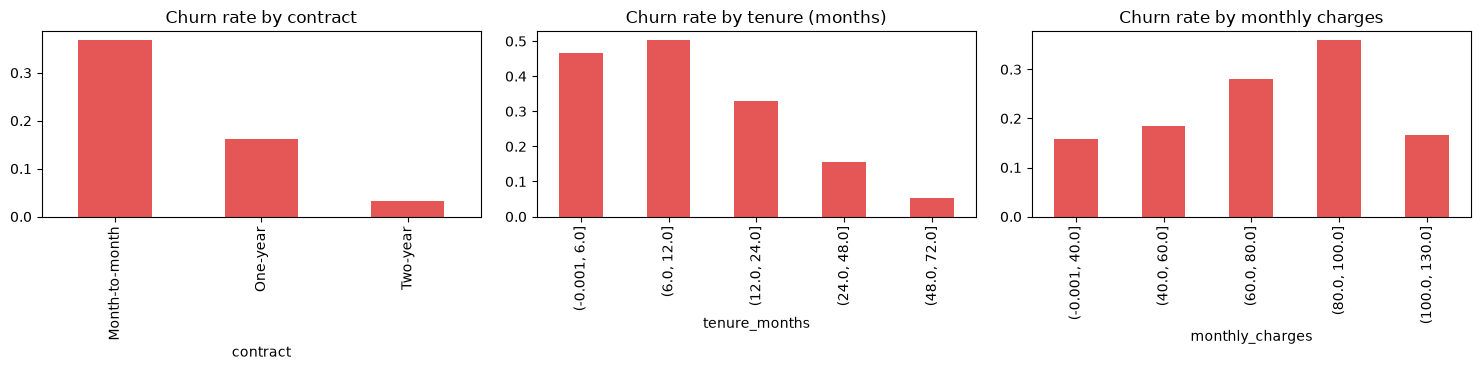

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
df.groupby("contract")["churn"].mean().plot.bar(ax=axes[0], color="#E45756", title="Churn rate by contract")
df.groupby(pd.cut(df["tenure_months"], [0, 6, 12, 24, 48, 72], include_lowest=True), observed=True)["churn"].mean().plot.bar(
    ax=axes[1], color="#E45756", title="Churn rate by tenure (months)")
df.groupby(pd.cut(df["monthly_charges"], [0, 40, 60, 80, 100, 130], include_lowest=True), observed=True)["churn"].mean().plot.bar(
    ax=axes[2], color="#E45756", title="Churn rate by monthly charges")
plt.tight_layout(); plt.show()

## 4. Split the data (80/20, stratified)
Scalers and encoders are part of the pipeline, so they are fitted on training data only.

In [7]:
X_train, X_test, y_train, y_test = pp.split_data(df)
print(len(X_train), len(X_test), round(y_train.mean(), 3), round(y_test.mean(), 3))

1200 300 0.248 0.25


## 5. Train models (class_weight handles the imbalance)

In [8]:
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
}
fitted = {n: Pipeline([("prep", pp.build_preprocessor()), ("model", m)]).fit(X_train, y_train)
          for n, m in models.items()}

## 6. Evaluate on the test set - not just accuracy

In [9]:
rows = []
for name, pipe in fitted.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({"model": name, "accuracy": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, proba)})
pd.DataFrame(rows).round(3)

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.743,0.491,0.733,0.588,0.794
1,Random Forest,0.730,0.473,0.707,0.567,0.783


In [10]:
pipe = fitted["Logistic Regression"]
proba = pipe.predict_proba(X_test)[:, 1]
print(classification_report(y_test, (proba >= 0.5).astype(int), target_names=["stayed", "churned"]))
print(confusion_matrix(y_test, (proba >= 0.5).astype(int)))

              precision    recall  f1-score   support

      stayed       0.89      0.75      0.81       225
     churned       0.49      0.73      0.59        75

    accuracy                           0.74       300
   macro avg       0.69      0.74      0.70       300
weighted avg       0.79      0.74      0.76       300

[[168  57]
 [ 20  55]]


## 7. Decision threshold
A lower threshold catches more churners but raises more false alarms. (The script `src/train_model.py` picks the threshold with cross-validation on the training data.)

In [11]:
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= t).astype(int)
    print(f"threshold {t:.1f}: precision={precision_score(y_test, pred):.2f} "
          f"recall={recall_score(y_test, pred):.2f} f1={f1_score(y_test, pred):.2f}")

threshold 0.3: precision=0.36 recall=0.89 f1=0.51
threshold 0.4: precision=0.39 recall=0.79 f1=0.52
threshold 0.5: precision=0.49 recall=0.73 f1=0.59
threshold 0.6: precision=0.50 recall=0.60 f1=0.55
threshold 0.7: precision=0.58 recall=0.45 f1=0.51


## 8. What drives churn in this data?
A pattern in the data does not prove the cause.

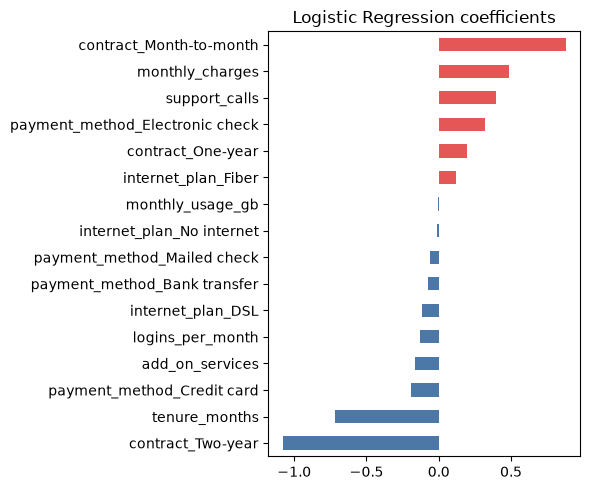

In [12]:
names = [n.split("__", 1)[1] for n in pipe.named_steps["prep"].get_feature_names_out()]
coef = pd.Series(pipe.named_steps["model"].coef_[0], index=names).sort_values()
coef.plot.barh(figsize=(6, 5), color=["#4C78A8" if v < 0 else "#E45756" for v in coef], title="Logistic Regression coefficients")
plt.tight_layout(); plt.show()

## 9. Predictions with probabilities and limitations

In [13]:
out = pd.DataFrame({"customer_id": df.loc[X_test.index, "customer_id"].values,
                    "churn_probability": proba.round(3),
                    "risk_label": [risk_label(p) for p in proba]}).sort_values("churn_probability", ascending=False)
out.head(10)
print()
print(LIMITATIONS)


These are estimates based on sample data and past patterns. They are not certain, and some predictions will be wrong.
